# Binding Affinity Prediction from Docking Features
Predicts `neg_log10_affinity_M` (and optionally `affinity_Kd_nM`) from ligand physicochemical and docking score features using ensemble ML models.

In [ ]:
# Install dependencies if needed
# !pip install pandas numpy scikit-learn xgboost shap matplotlib seaborn

## 1. Load & Inspect Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ── CONFIG ──────────────────────────────────────────────────────────────────
DATA_PATH   = "combined_30k.csv"          # <-- update this
TARGET_COL  = "neg_log10_affinity_M"  # switch to "affinity_Kd_nM" if preferred
RANDOM_SEED = 42
# ────────────────────────────────────────────────────────────────────────────

df = pd.read_csv(DATA_PATH, sep=None, engine="python")  # handles tab or comma
print(df.shape)
df.head()

(29411, 20)


,Job_ID,molecular_weight,logP,num_h_donors,num_h_acceptors,num_rotatable_bonds,tpsa,num_rings,num_aromatic_rings,num_atoms,num_heavy_atoms,formal_charge,score,total,vdw,elec,desolv,bsa,neg_log10_affinity_M,iptm
0,dock_1,312.538,7.1127,1,2,19,37.30,0,0,62,22,0,-89.935,-218.023,-48.388,-169.635,-7.620,830.568,7.585027,0.85
1,dock_2,301.251,-1.2265,4,8,8,142.52,2,1,36,21,0,-28.529,-31.946,-25.239,-6.707,-1.949,476.808,3.301030,0.89
2,dock_3,406.438,4.8204,3,6,11,104.82,4,3,52,30,0,-47.412,-51.750,-45.487,-6.263,-0.672,752.575,7.638272,0.96
3,dock_4,520.563,-1.8802,7,9,18,222.13,2,0,71,37,1,-80.642,-197.802,-44.507,-153.295,-5.476,989.693,5.191789,0.61
4,dock_5,569.524,-4.5727,7,13,12,253.76,4,1,71,40,0,-29.119,-3.597,-31.511,27.915,-3.190,615.462,6.732828,0.80


In [16]:
# Filter for runs with IPTM greater than or equal to 0.70
df = df[df['iptm'] >= 0.70]

## 2. Feature Engineering & Cleaning

In [2]:
# Physicochemical (Lipinski / ADMET-like) features
PHYSCHEM_FEATURES = [
    "molecular_weight", "logP", "num_h_donors", "num_h_acceptors",
    "num_rotatable_bonds", "tpsa", "num_rings", "num_aromatic_rings",
    "num_atoms", "num_heavy_atoms", "formal_charge"
]

# Docking energy components
DOCKING_FEATURES = ["score", "total", "vdw", "elec", "desolv", "bsa"]

FEATURES = PHYSCHEM_FEATURES + DOCKING_FEATURES

# Drop rows missing target or all features
df_clean = df[FEATURES + [TARGET_COL]].dropna(subset=[TARGET_COL])

# Impute remaining NaNs with median (rare missing values in descriptors)
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
X = pd.DataFrame(imputer.fit_transform(df_clean[FEATURES]), columns=FEATURES)
y = df_clean[TARGET_COL].values

print(f"Samples: {len(X)}  |  Features: {X.shape[1]}  |  Target: {TARGET_COL}")
print(f"Target range: {y.min():.2f} – {y.max():.2f}  |  mean: {y.mean():.2f}")

Samples: 29411  |  Features: 17  |  Target: neg_log10_affinity_M
Target range: 0.40 – 15.00  |  mean: 6.42


## 3. Exploratory Data Analysis

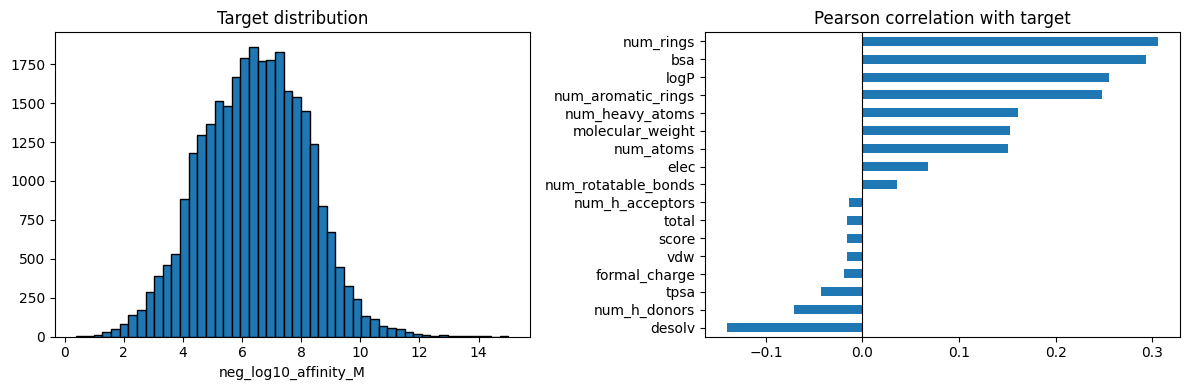

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y, bins=50, edgecolor="k")
axes[0].set_xlabel(TARGET_COL)
axes[0].set_title("Target distribution")

corr = X.corrwith(pd.Series(y, name=TARGET_COL)).sort_values()
corr.plot(kind="barh", ax=axes[1])
axes[1].set_title("Pearson correlation with target")
axes[1].axvline(0, color="k", linewidth=0.8)

plt.tight_layout()
plt.show()

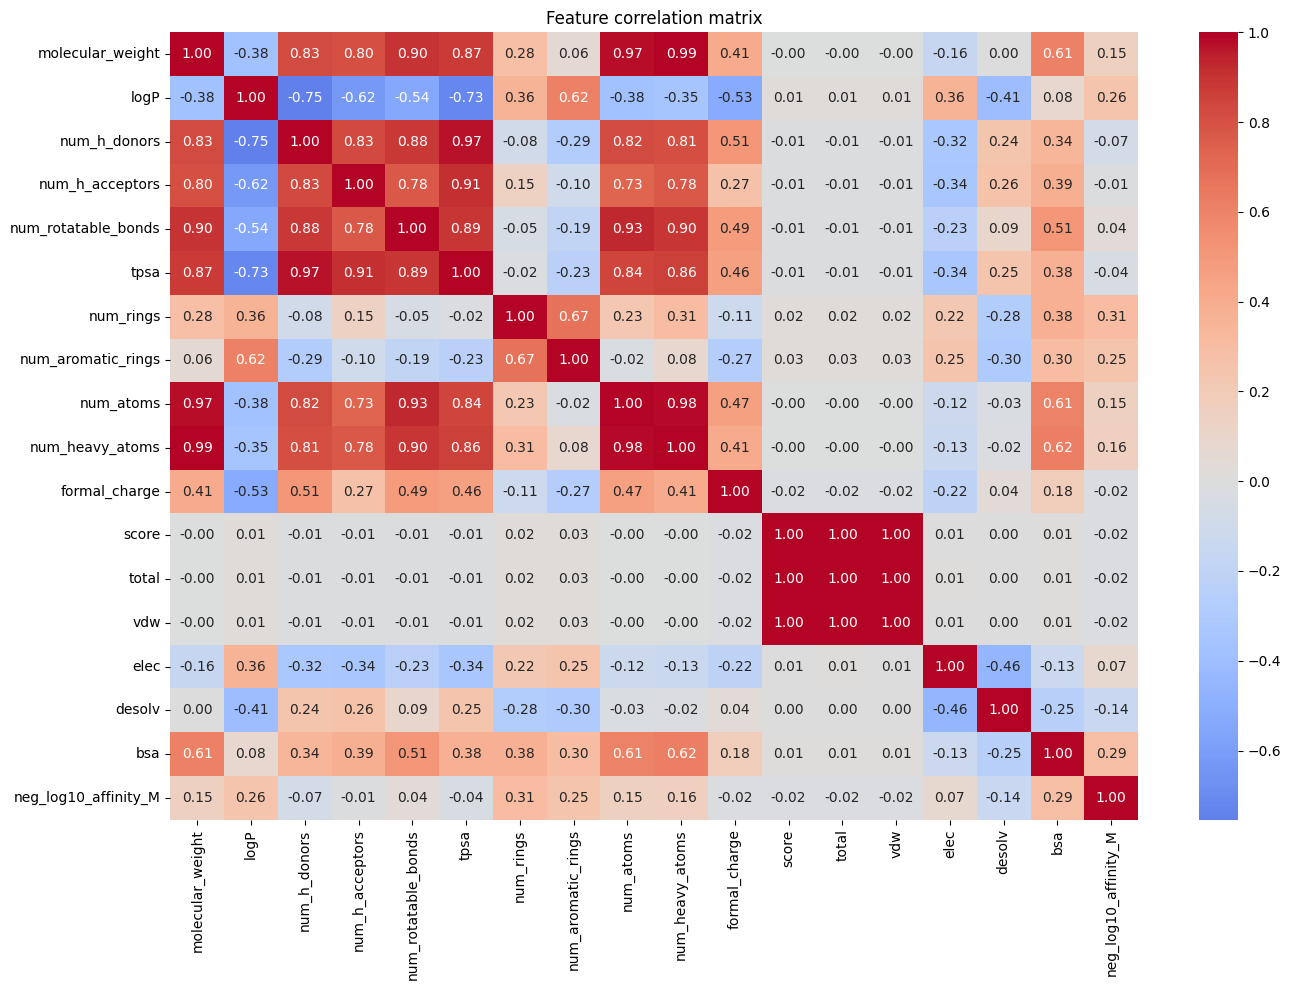

In [4]:
# Correlation heatmap (features + target)
corr_matrix = pd.concat([X, pd.Series(y, name=TARGET_COL)], axis=1).corr()
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()

## 4. Train / Test Split

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED
)
print(f"Train: {len(X_train)}  |  Test: {len(X_test)}")

Train: 23528  |  Test: 5883


## A. Dataset Comparison: 20k vs 30k
Train and evaluate all models on both dataset sizes to compare performance.

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             roc_auc_score, precision_score, recall_score, f1_score,
                             average_precision_score)
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
import xgboost as xgb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

PHYSCHEM_FEATURES = [
    "molecular_weight", "logP", "num_h_donors", "num_h_acceptors",
    "num_rotatable_bonds", "tpsa", "num_rings", "num_aromatic_rings",
    "num_atoms", "num_heavy_atoms", "formal_charge"
]
DOCKING_FEATURES = ["score", "total", "vdw", "elec", "desolv", "bsa"]
FEATURES = PHYSCHEM_FEATURES + DOCKING_FEATURES
TARGET_COL = "neg_log10_affinity_M"
RANDOM_SEED = 42
IPTM_THRESHOLD = 0.70

def load_and_prep(path, iptm_thresh=IPTM_THRESHOLD):
    df = pd.read_csv(path, sep=None, engine="python")
    df = df[df["iptm"] >= iptm_thresh]
    df_clean = df[FEATURES + [TARGET_COL]].dropna(subset=[TARGET_COL])
    imp = SimpleImputer(strategy="median")
    X = pd.DataFrame(imp.fit_transform(df_clean[FEATURES]), columns=FEATURES)
    y = df_clean[TARGET_COL].values
    return X, y, imp

def make_models():
    return {
        "Ridge": Pipeline([
            ("scaler", StandardScaler()),
            ("model",  Ridge(alpha=1.0))
        ]),
        "Random Forest": RandomForestRegressor(
            n_estimators=300, max_features="sqrt",
            n_jobs=-1, random_state=RANDOM_SEED
        ),
        "XGBoost": xgb.XGBRegressor(
            n_estimators=500, learning_rate=0.05,
            max_depth=6, subsample=0.8,
            colsample_bytree=0.8, n_jobs=-1,
            random_state=RANDOM_SEED, verbosity=0
        )
    }

def compute_metrics(y_true, y_pred, label=""):
    """Compute regression + binarised classification metrics."""
    r2   = r2_score(y_true, y_pred)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # Binarise at median for classification-style metrics
    median_val = np.median(y_true)
    y_bin_true = (y_true  >= median_val).astype(int)
    y_bin_pred = (y_pred  >= median_val).astype(int)

    precision = precision_score(y_bin_true, y_bin_pred, zero_division=0)
    recall    = recall_score(y_bin_true, y_bin_pred, zero_division=0)
    f1        = f1_score(y_bin_true, y_bin_pred, zero_division=0)
    try:
        auc_roc = roc_auc_score(y_bin_true, y_pred)
    except Exception:
        auc_roc = float("nan")

    return dict(Label=label, R2=r2, MAE=mae, RMSE=rmse,
                AUC_ROC=auc_roc, Precision=precision,
                Recall=recall, F1=f1)

print("Loading datasets...")
X_20k, y_20k, imp_20k = load_and_prep("combined_20k.csv")
X_30k, y_30k, imp_30k = load_and_prep("combined_30k.csv")
print(f"20k dataset: {len(X_20k)} samples after iptm filter")
print(f"30k dataset: {len(X_30k)} samples after iptm filter")


Loading datasets...
20k dataset: 18616 samples after iptm filter
30k dataset: 27293 samples after iptm filter


In [8]:
# ── Train & evaluate on 20k ──
X_tr20, X_te20, y_tr20, y_te20 = train_test_split(X_20k, y_20k, test_size=0.2, random_state=RANDOM_SEED)
models_20k = make_models()
results_20k = {}
for name, mdl in models_20k.items():
    mdl.fit(X_tr20, y_tr20)
    preds = mdl.predict(X_te20)
    results_20k[name] = {**compute_metrics(y_te20, preds, label=name), "preds": preds}

# ── Train & evaluate on 30k ──
X_tr30, X_te30, y_tr30, y_te30 = train_test_split(X_30k, y_30k, test_size=0.2, random_state=RANDOM_SEED)
models_30k = make_models()
results_30k = {}
for name, mdl in models_30k.items():
    mdl.fit(X_tr30, y_tr30)
    preds = mdl.predict(X_te30)
    results_30k[name] = {**compute_metrics(y_te30, preds, label=name), "preds": preds}

# ── Summary table ──
metric_cols = ["R2", "MAE", "RMSE", "AUC_ROC", "Precision", "Recall", "F1"]

rows = []
for name in results_20k:
    r20 = results_20k[name]
    r30 = results_30k[name]
    rows.append({"Model": name, "Dataset": "20k", **{m: r20[m] for m in metric_cols}})
    rows.append({"Model": name, "Dataset": "30k", **{m: r30[m] for m in metric_cols}})

summary_df = pd.DataFrame(rows).set_index(["Model", "Dataset"])
print("\n=== 20k vs 30k Full Metrics ===")
print(summary_df.round(4).to_string())



=== 20k vs 30k Full Metrics ===
                           R2     MAE    RMSE  AUC_ROC  Precision  Recall      F1
Model         Dataset                                                            
Ridge         20k      0.2713  1.3106  1.6390   0.7565     0.7041  0.6928  0.6984
              30k      0.1938  1.2539  1.5801   0.7100     0.6649  0.6608  0.6629
Random Forest 20k      0.4863  1.0794  1.3762   0.8429     0.7603  0.7750  0.7676
              30k      0.4654  0.9951  1.2868   0.8279     0.7442  0.7516  0.7479
XGBoost       20k      0.4603  1.1164  1.4106   0.8280     0.7422  0.7653  0.7536
              30k      0.4235  1.0459  1.3362   0.8043     0.7177  0.7534  0.7351


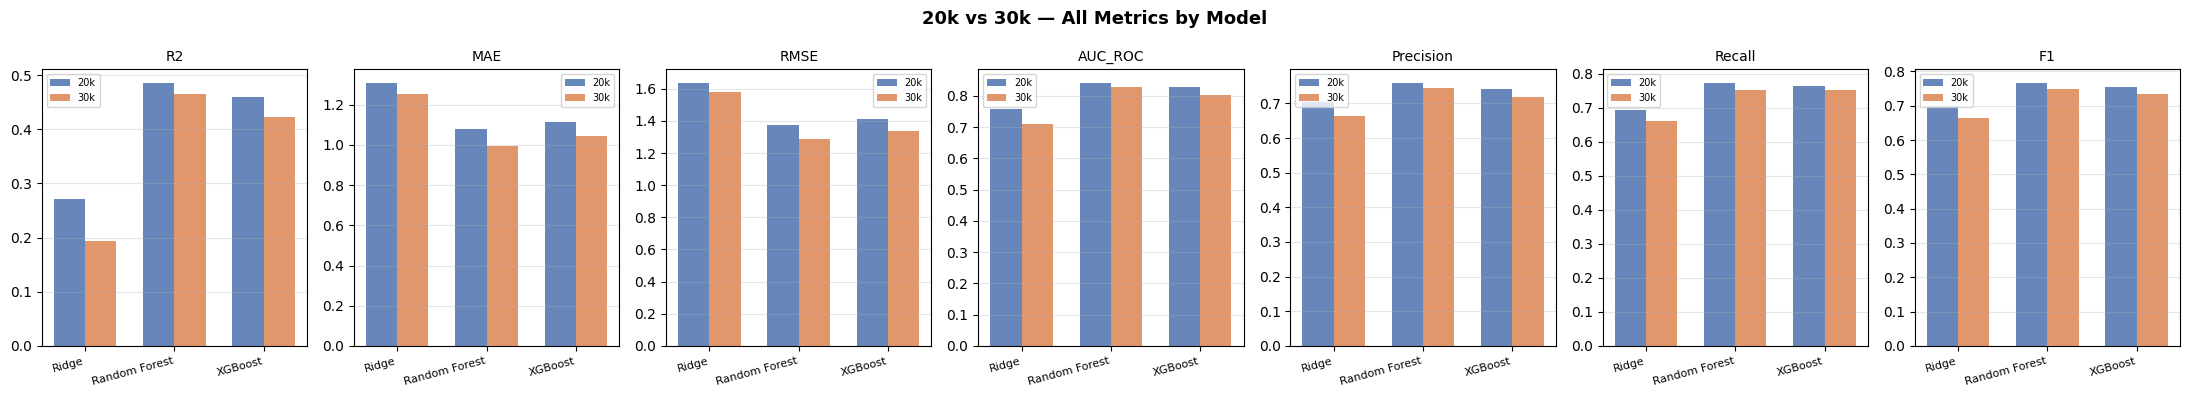

In [9]:
# ── Bar chart: R² by model & dataset size ──
fig, axes = plt.subplots(1, len(metric_cols), figsize=(22, 4))
model_names = list(results_20k.keys())
x = np.arange(len(model_names))
width = 0.35

for ax, metric in zip(axes, metric_cols):
    vals_20 = [results_20k[n][metric] for n in model_names]
    vals_30 = [results_30k[n][metric] for n in model_names]
    ax.bar(x - width/2, vals_20, width, label="20k", color="#4C72B0", alpha=0.85)
    ax.bar(x + width/2, vals_30, width, label="30k", color="#DD8452", alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(model_names, rotation=15, ha="right", fontsize=8)
    ax.set_title(metric, fontsize=10)
    ax.legend(fontsize=7)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("20k vs 30k — All Metrics by Model", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


## 5. Model Training
Three complementary models: Random Forest, XGBoost, and a regularised linear baseline (Ridge).

In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import xgboost as xgb

models = {
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  Ridge(alpha=1.0))
    ]),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, max_features="sqrt",
        n_jobs=-1, random_state=RANDOM_SEED
    ),
    "XGBoost": xgb.XGBRegressor(
        n_estimators=500, learning_rate=0.05,
        max_depth=6, subsample=0.8,
        colsample_bytree=0.8, n_jobs=-1,
        random_state=RANDOM_SEED, verbosity=0
    )
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    results[name] = {
        "R2":   r2_score(y_test, preds),
        "MAE":  mean_absolute_error(y_test, preds),
        "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "preds": preds
    }
    print(f"{name:>15}  R²={results[name]['R2']:.3f}  MAE={results[name]['MAE']:.3f}  RMSE={results[name]['RMSE']:.3f}")

          Ridge  R²=0.185  MAE=1.278  RMSE=1.592
  Random Forest  R²=0.456  MAE=1.018  RMSE=1.300
        XGBoost  R²=0.416  MAE=1.063  RMSE=1.347


## 6. Cross-validated Performance

In [11]:
from sklearn.model_selection import cross_val_score

print("5-fold CV R² (full dataset):")
for name, model in models.items():
    cv_scores = cross_val_score(model, X, y, cv=5, scoring="r2", n_jobs=-1)
    print(f"  {name:>15}: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

5-fold CV R² (full dataset):
            Ridge: 0.149 ± 0.075
    Random Forest: 0.348 ± 0.103
          XGBoost: 0.327 ± 0.093


## B. Extended Model Evaluation
Regression metrics (R², MAE, RMSE) plus binarised classification metrics (AUC-ROC, Precision, Recall, F1) on the 30k test set.

=== Extended Metrics — 30k Test Set ===
                   R2     MAE    RMSE  AUC_ROC  Precision  Recall      F1
Model                                                                    
Ridge          0.1938  1.2539  1.5801   0.7100     0.6649  0.6608  0.6629
Random Forest  0.4654  0.9951  1.2868   0.8279     0.7442  0.7516  0.7479
XGBoost        0.4235  1.0459  1.3362   0.8043     0.7177  0.7534  0.7351


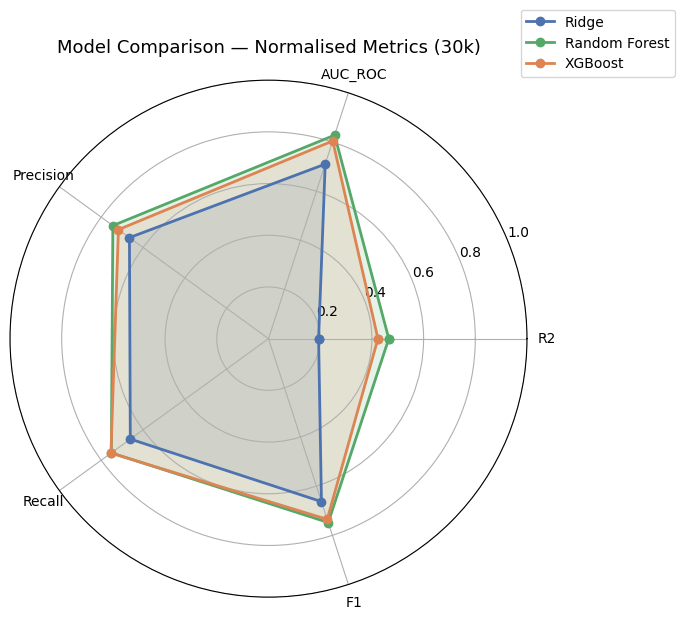

In [12]:
# Reuse results_30k from Section A for extended metrics display
# (If running this section standalone, re-train models_30k first)

metric_cols = ["R2", "MAE", "RMSE", "AUC_ROC", "Precision", "Recall", "F1"]
ext_rows = []
for name in results_30k:
    row = {m: results_30k[name][m] for m in metric_cols}
    ext_rows.append({"Model": name, **row})

ext_df = pd.DataFrame(ext_rows).set_index("Model")
print("=== Extended Metrics — 30k Test Set ===")
print(ext_df.round(4).to_string())

# Radar / spider chart of normalised metrics (higher = better for all)
from matplotlib.patches import FancyArrowPatch

display_metrics = ["R2", "AUC_ROC", "Precision", "Recall", "F1"]
angles = np.linspace(0, 2 * np.pi, len(display_metrics), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
colors = ["#4C72B0", "#55A868", "#DD8452"]

for (name, row), color in zip(ext_df[display_metrics].iterrows(), colors):
    vals = row.tolist() + row.tolist()[:1]
    ax.plot(angles, vals, "o-", linewidth=2, label=name, color=color)
    ax.fill(angles, vals, alpha=0.15, color=color)

ax.set_thetagrids(np.degrees(angles[:-1]), display_metrics)
ax.set_ylim(0, 1)
ax.set_title("Model Comparison — Normalised Metrics (30k)", size=13, pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.15))
plt.tight_layout()
plt.show()


## C. Random Forest — Cross-Validation & Hyperparameter Tuning
Focus on the best-performing model with 5-fold CV and RandomizedSearchCV.

=== Random Forest — 5-fold Cross-Validation (30k) ===
  Train R²  : 0.9270 ± 0.0017
  Test  R²  : 0.3508 ± 0.1031
  Test  MAE : 1.1082
  Test  RMSE: 1.3992


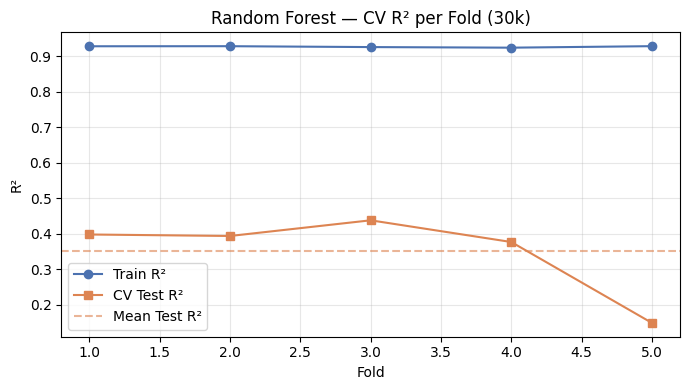

In [13]:
from sklearn.model_selection import RandomizedSearchCV, cross_validate

print("=== Random Forest — 5-fold Cross-Validation (30k) ===")
rf_base = RandomForestRegressor(
    n_estimators=300, max_features="sqrt",
    n_jobs=-1, random_state=RANDOM_SEED
)

cv_results = cross_validate(
    rf_base, X_30k, y_30k, cv=5,
    scoring=["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"],
    return_train_score=True, n_jobs=-1
)

print(f"  Train R²  : {cv_results['train_r2'].mean():.4f} ± {cv_results['train_r2'].std():.4f}")
print(f"  Test  R²  : {cv_results['test_r2'].mean():.4f} ± {cv_results['test_r2'].std():.4f}")
print(f"  Test  MAE : {-cv_results['test_neg_mean_absolute_error'].mean():.4f}")
print(f"  Test  RMSE: {-cv_results['test_neg_root_mean_squared_error'].mean():.4f}")

# Plot fold-by-fold R²
fig, ax = plt.subplots(figsize=(7, 4))
folds = range(1, 6)
ax.plot(folds, cv_results["train_r2"], "o-", label="Train R²", color="#4C72B0")
ax.plot(folds, cv_results["test_r2"],  "s-", label="CV Test R²", color="#DD8452")
ax.axhline(cv_results["test_r2"].mean(), color="#DD8452", linestyle="--", alpha=0.6, label="Mean Test R²")
ax.set_xlabel("Fold")
ax.set_ylabel("R²")
ax.set_title("Random Forest — CV R² per Fold (30k)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [14]:
# ── RandomizedSearchCV for Random Forest ──
print("Running RandomizedSearchCV for Random Forest (this may take a few minutes)...")

rf_param_dist = {
    "n_estimators":     [100, 200, 300, 500],
    "max_depth":        [None, 10, 20, 30],
    "max_features":     ["sqrt", "log2", 0.5],
    "min_samples_split":[2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "bootstrap":        [True, False],
}

rf_search = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=-1, random_state=RANDOM_SEED),
    rf_param_dist,
    n_iter=30, cv=5, scoring="r2",
    random_state=RANDOM_SEED, n_jobs=-1, verbose=1
)
rf_search.fit(X_tr30, y_tr30)

print(f"\nBest CV R²   : {rf_search.best_score_:.4f}")
print(f"Best params  : {rf_search.best_params_}")

# Evaluate tuned model
rf_tuned_preds = rf_search.best_estimator_.predict(X_te30)
tuned_metrics  = compute_metrics(y_te30, rf_tuned_preds, label="RF Tuned")
base_metrics   = compute_metrics(y_te30, results_30k["Random Forest"]["preds"], label="RF Base")

comp_df = pd.DataFrame([base_metrics, tuned_metrics]).set_index("Label")
print("\n=== Base vs Tuned Random Forest (30k test set) ===")
print(comp_df[["R2","MAE","RMSE","AUC_ROC","Precision","Recall","F1"]].round(4).to_string())


Running RandomizedSearchCV for Random Forest (this may take a few minutes)...
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best CV R²   : 0.4545
Best params  : {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None, 'bootstrap': False}

=== Base vs Tuned Random Forest (30k test set) ===
              R2     MAE    RMSE  AUC_ROC  Precision  Recall      F1
Label                                                               
RF Base   0.4654  0.9951  1.2868   0.8279     0.7442  0.7516  0.7479
RF Tuned  0.4743  0.9806  1.2760   0.8313     0.7525  0.7574  0.7549


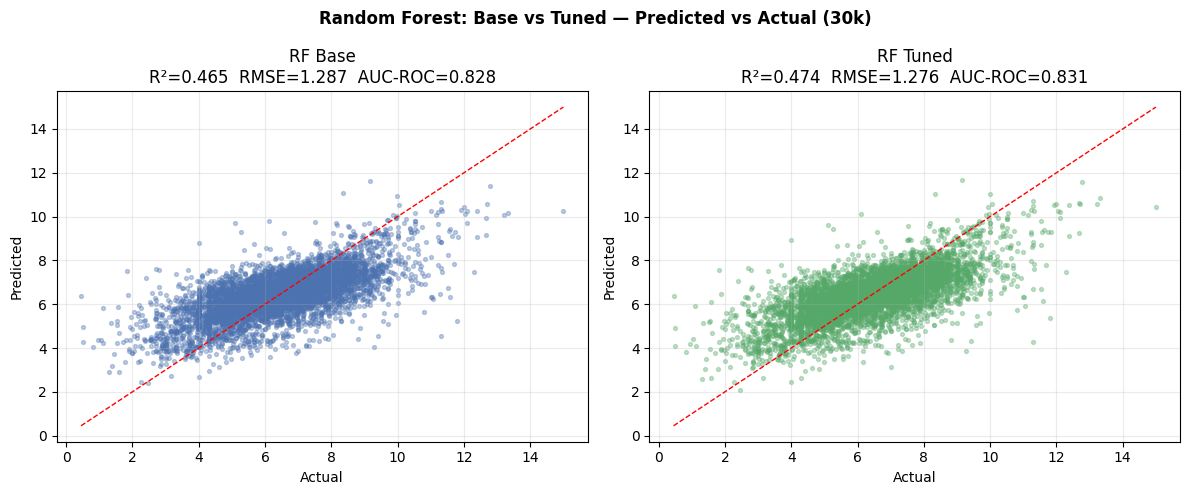

In [15]:
# ── Predicted vs Actual: Base vs Tuned RF ──
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (preds, label, color) in zip(axes, [
    (results_30k["Random Forest"]["preds"], "RF Base",  "#4C72B0"),
    (rf_tuned_preds,                        "RF Tuned", "#55A868"),
]):
    m = compute_metrics(y_te30, preds)
    ax.scatter(y_te30, preds, alpha=0.35, s=8, color=color)
    lims = [min(y_te30.min(), preds.min()), max(y_te30.max(), preds.max())]
    ax.plot(lims, lims, "r--", linewidth=1)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.set_title(f"{label}\nR²={m['R2']:.3f}  RMSE={m['RMSE']:.3f}  AUC-ROC={m['AUC_ROC']:.3f}")
    ax.grid(alpha=0.25)

plt.suptitle("Random Forest: Base vs Tuned — Predicted vs Actual (30k)", fontweight="bold")
plt.tight_layout()
plt.show()


## D. IPTM Threshold Sweep
Sweep iptm from 0.0 to 0.90 in steps of 0.05 and record each model's R² on the 30k dataset. Helps identify the optimal confidence cutoff.

In [16]:
print("Sweeping iptm thresholds (0.00 → 0.90)...")

thresholds = np.arange(0.0, 0.91, 0.05)
sweep_records = []

# Load raw 30k (no iptm filter yet)
df_raw30 = pd.read_csv("combined_30k.csv", sep=None, engine="python")
print(f"Raw 30k rows: {len(df_raw30)}")

for thresh in thresholds:
    df_t = df_raw30[df_raw30["iptm"] >= thresh]
    df_clean = df_t[FEATURES + [TARGET_COL]].dropna(subset=[TARGET_COL])
    if len(df_clean) < 50:
        print(f"  thresh={thresh:.2f}: too few samples ({len(df_clean)}), skipping")
        continue

    imp_t = SimpleImputer(strategy="median")
    X_t = pd.DataFrame(imp_t.fit_transform(df_clean[FEATURES]), columns=FEATURES)
    y_t = df_clean[TARGET_COL].values

    X_tr, X_te, y_tr, y_te = train_test_split(X_t, y_t, test_size=0.2, random_state=RANDOM_SEED)
    rec = {"iptm_threshold": thresh, "n_samples": len(X_t)}

    for name, mdl in make_models().items():
        mdl.fit(X_tr, y_tr)
        preds = mdl.predict(X_te)
        rec[name] = r2_score(y_te, preds)

    sweep_records.append(rec)
    print(f"  thresh={thresh:.2f}  n={len(X_t):>5}  RF={rec['Random Forest']:.3f}  XGB={rec['XGBoost']:.3f}  Ridge={rec['Ridge']:.3f}")

sweep_df = pd.DataFrame(sweep_records)
print("\nDone.")


Sweeping iptm thresholds (0.00 → 0.90)...
Raw 30k rows: 29411
  thresh=0.00  n=29411  RF=0.456  XGB=0.416  Ridge=0.185
  thresh=0.05  n=29411  RF=0.456  XGB=0.416  Ridge=0.185
  thresh=0.10  n=29411  RF=0.456  XGB=0.416  Ridge=0.185
  thresh=0.15  n=29411  RF=0.456  XGB=0.416  Ridge=0.185


KeyboardInterrupt: 

In [ ]:
# ── Scatter plot: R² vs iptm threshold ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

model_colors = {"Ridge": "#4C72B0", "Random Forest": "#55A868", "XGBoost": "#DD8452"}

ax = axes[0]
for name, color in model_colors.items():
    ax.plot(sweep_df["iptm_threshold"], sweep_df[name], "o-", label=name,
            color=color, linewidth=2, markersize=6)
ax.axvline(IPTM_THRESHOLD, color="gray", linestyle="--", linewidth=1, label=f"Default ({IPTM_THRESHOLD})")
ax.set_xlabel("iptm Threshold")
ax.set_ylabel("R²")
ax.set_title("R² vs iptm Threshold — All Models (30k)")
ax.legend()
ax.grid(alpha=0.3)

ax2 = axes[1]
ax2.bar(sweep_df["iptm_threshold"], sweep_df["n_samples"],
        width=0.04, color="#9C9EDE", alpha=0.8, label="Samples")
ax2.axvline(IPTM_THRESHOLD, color="gray", linestyle="--", linewidth=1, label=f"Default ({IPTM_THRESHOLD})")
ax2.set_xlabel("iptm Threshold")
ax2.set_ylabel("Samples Retained")
ax2.set_title("Sample Size vs iptm Threshold (30k)")
ax2.legend()
ax2.grid(axis="y", alpha=0.3)

plt.suptitle("iptm Threshold Sensitivity Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Best threshold per model
for name in model_colors:
    best_idx = sweep_df[name].idxmax()
    best_row = sweep_df.loc[best_idx]
    print(f"{name:>15}: best R²={best_row[name]:.4f} at iptm≥{best_row['iptm_threshold']:.2f}  (n={int(best_row['n_samples'])})")


## 7. Predicted vs Actual Plots

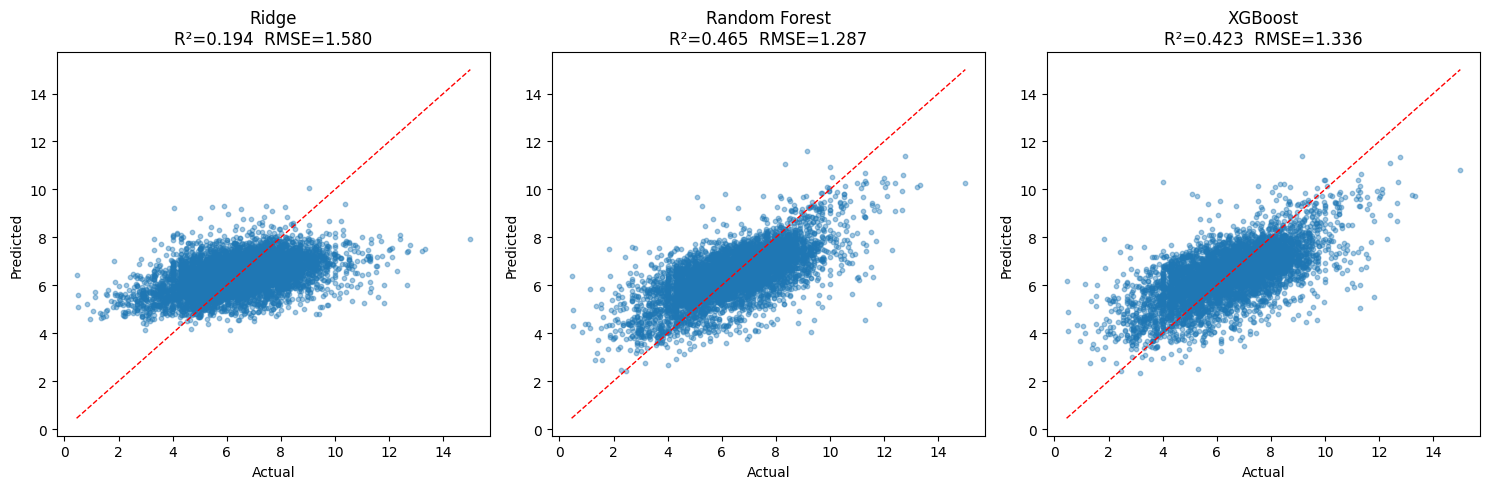

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, res) in zip(axes, results.items()):
    ax.scatter(y_test, res["preds"], alpha=0.4, s=10)
    lims = [min(y_test.min(), res["preds"].min()),
            max(y_test.max(), res["preds"].max())]
    ax.plot(lims, lims, "r--", linewidth=1)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")
    ax.set_title(f"{name}\nR²={res['R2']:.3f}  RMSE={res['RMSE']:.3f}")
plt.tight_layout()
plt.show()

## 8. Feature Importance

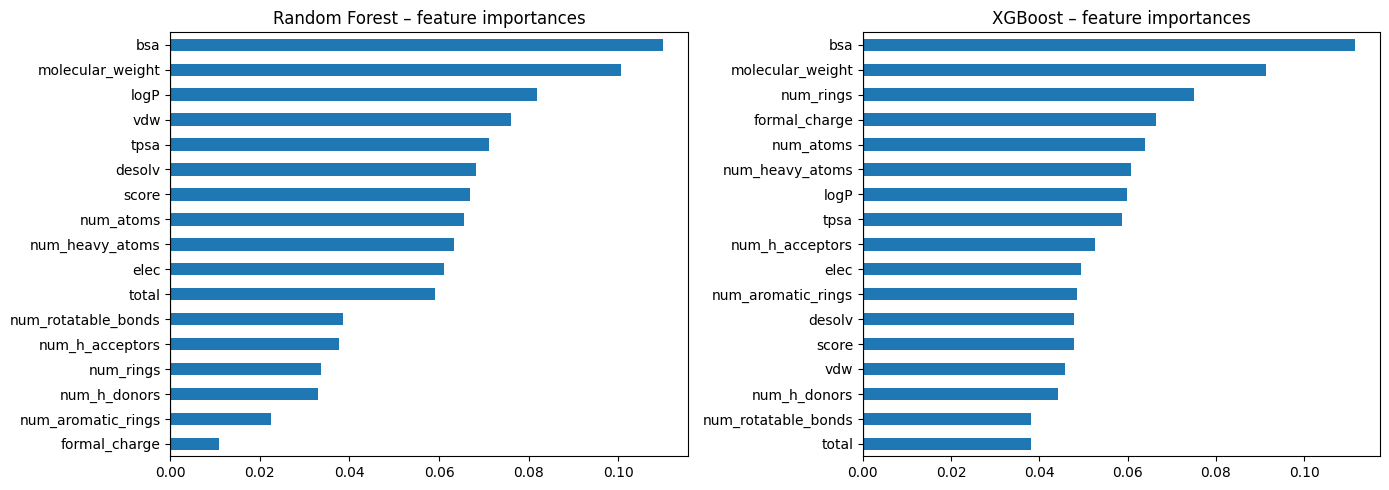

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, key in zip(axes, ["Random Forest", "XGBoost"]):
    importances = pd.Series(
        models[key].feature_importances_, index=FEATURES
    ).sort_values(ascending=True)
    importances.plot(kind="barh", ax=ax)
    ax.set_title(f"{key} – feature importances")
    ax.axvline(0, color="k", linewidth=0.8)

plt.tight_layout()
plt.show()

## 9. SHAP Explainability (XGBoost)

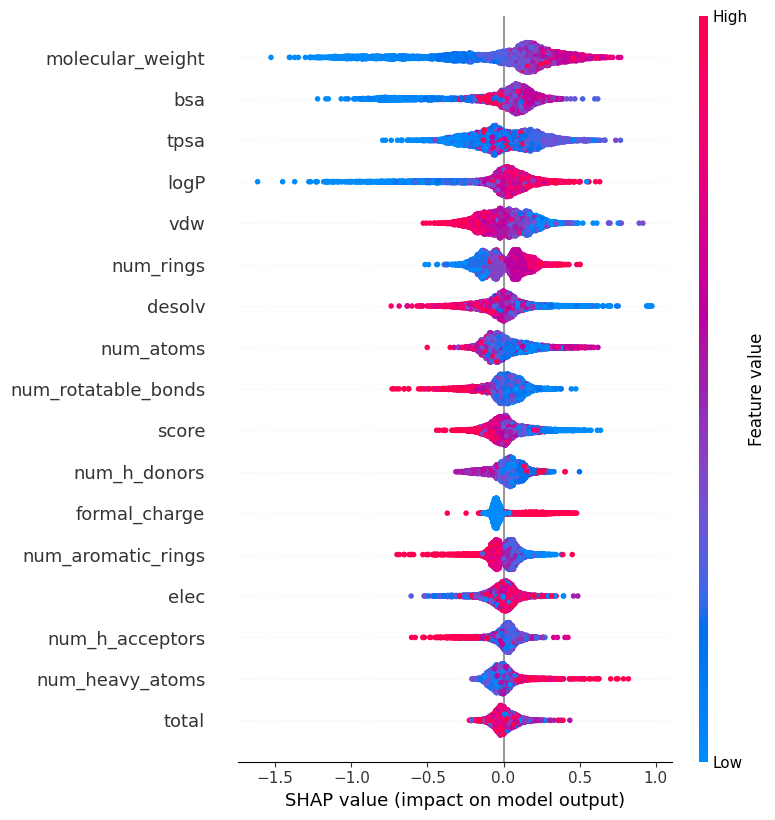

In [25]:
import shap

explainer   = shap.TreeExplainer(models["XGBoost"])
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, feature_names=FEATURES, show=True)

## 10. Hyperparameter Tuning (XGBoost – optional)

In [26]:
# Uncomment to run (can be slow on large datasets)

from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators":     [300, 500, 800],
    "max_depth":        [4, 6, 8],
    "learning_rate":    [0.01, 0.05, 0.1],
    "subsample":        [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
}

search = RandomizedSearchCV(
    xgb.XGBRegressor(n_jobs=-1, random_state=RANDOM_SEED, verbosity=0),
    param_dist, n_iter=30, cv=5, scoring="r2",
    random_state=RANDOM_SEED, n_jobs=-1, verbose=1
)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)
print("Best CV R²:", search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best params: {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV R²: 0.4278031100386134


## 11. Save the Best Model

In [27]:
import joblib

best_model_name = max(results, key=lambda k: results[k]["R2"])
print(f"Best model: {best_model_name}  (R²={results[best_model_name]['R2']:.3f})")

joblib.dump(models[best_model_name], "30k_best_binding_affinity_model.pkl")
print("Saved → 30k_best_binding_affinity_model.pkl")

Best model: Random Forest  (R²=0.465)
Saved → 30k_best_binding_affinity_model.pkl


## 12. Predict on New Compounds

In [ ]:
# Load model and predict on a new CSV
# new_df = pd.read_csv("new_compounds.csv", sep=None, engine="python")
# X_new  = pd.DataFrame(imputer.transform(new_df[FEATURES]), columns=FEATURES)
# best   = joblib.load("best_binding_affinity_model.pkl")
# new_df["predicted_" + TARGET_COL] = best.predict(X_new)
# new_df.to_csv("predictions.csv", index=False)
# new_df.head()